TensorFlow Version: 2.21.0
Dataset Loaded Successfully
Training Dataset Shape: (10000, 28, 28, 1)
Testing Dataset Shape: (10000, 28, 28, 1)

Training Classifier...
Epoch 1/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7190 - loss: 0.8113 - val_accuracy: 0.8170 - val_loss: 0.5545
Epoch 2/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8268 - loss: 0.4975 - val_accuracy: 0.8280 - val_loss: 0.4901
Epoch 3/3
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8468 - loss: 0.4333 - val_accuracy: 0.8290 - val_loss: 0.4775

========== TRAINING VAE ==========
VAE Epoch 1/3 | Loss: 393.0043
VAE Epoch 2/3 | Loss: 306.5569
VAE Epoch 3/3 | Loss: 292.1990

========== TRAINING GAN ==========
GAN Epoch 1/3 | Discriminator Loss: 1.1590 | Generator Loss: 0.7114
GAN Epoch 2/3 | Discriminator Loss: 1.3400 | Generator Loss: 0.7549
GAN Epoch 3/3 | Discriminator Loss: 1.2786 | Generator Loss: 0.8234

Generating 1000 VAE images...
Generating 1000 GAN images...
VAE Images: (1000, 28, 28, 1)

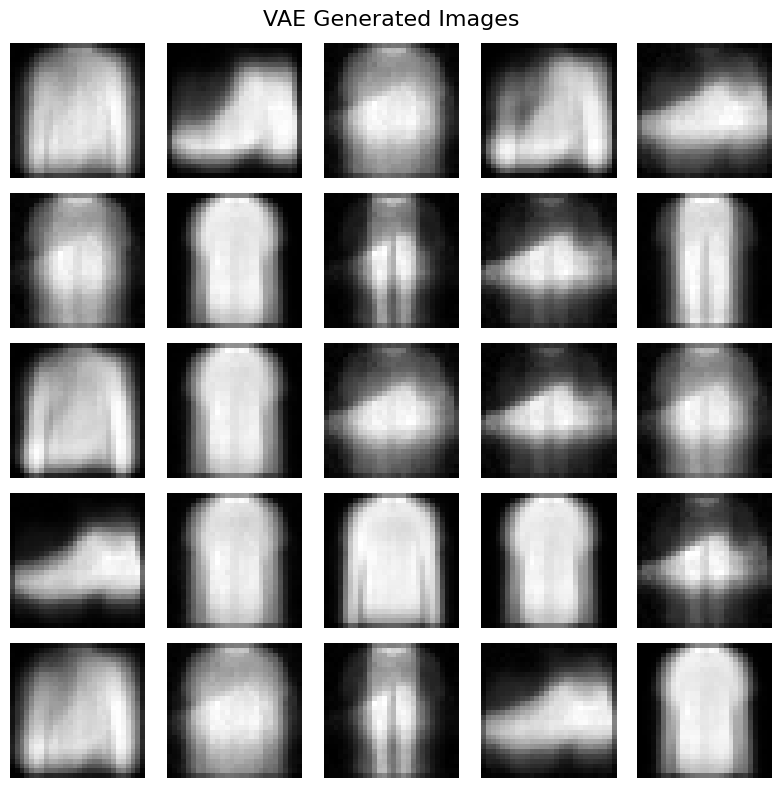

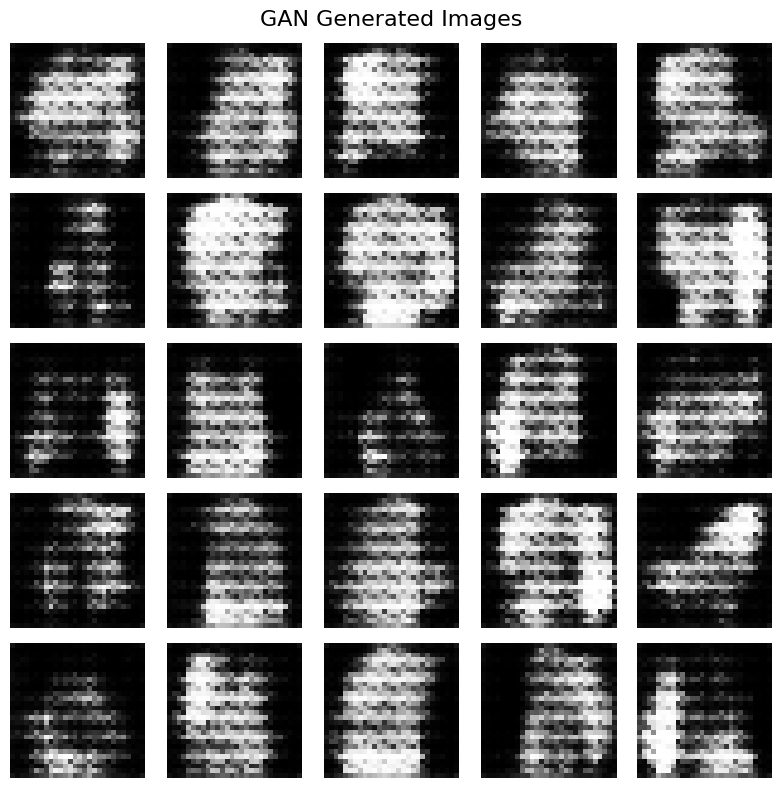


Classifying generated images...

Extracting features...

========== FINAL COMPARISON TABLE ==========


/tmp/ipykernel_53546/3408806863.py:522: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean = sqrtm(sigma1 @ sigma2)


,Evaluation Metric,VAE,GAN
0,Classifier-based Inception Score,2.4764,2.8346
1,FID Score,52.4679,31.4704
2,Diversity Entropy,1.4503,1.8407
3,Normalized Diversity,0.6299,0.7994
4,Class Coverage,6.0000,10.0000



Generated Class Distribution


,Fashion Category,VAE Generated Images,GAN Generated Images
0,T-shirt,0,95
1,Trouser,6,16
2,Pullover,0,3
3,Dress,145,61
4,Coat,0,18
5,Sandal,0,103
6,Shirt,293,303
7,Sneaker,64,29
8,Bag,387,264
9,Ankle boot,105,108


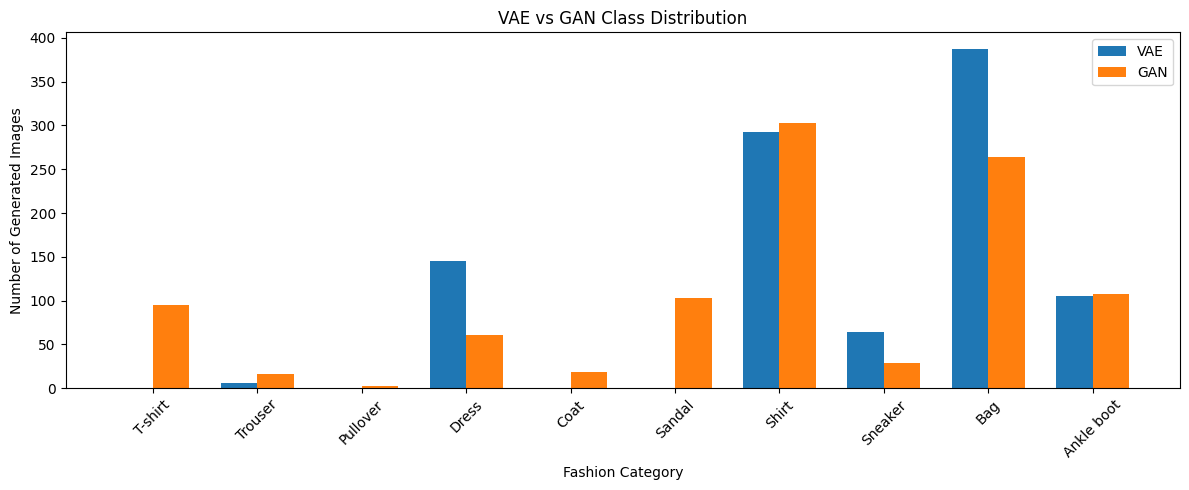

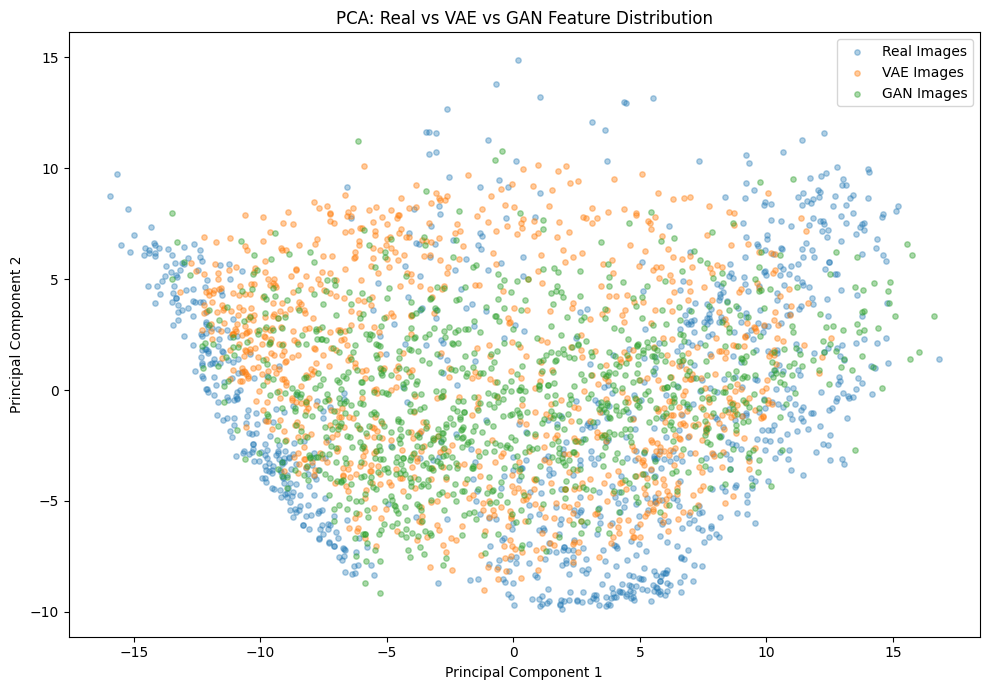

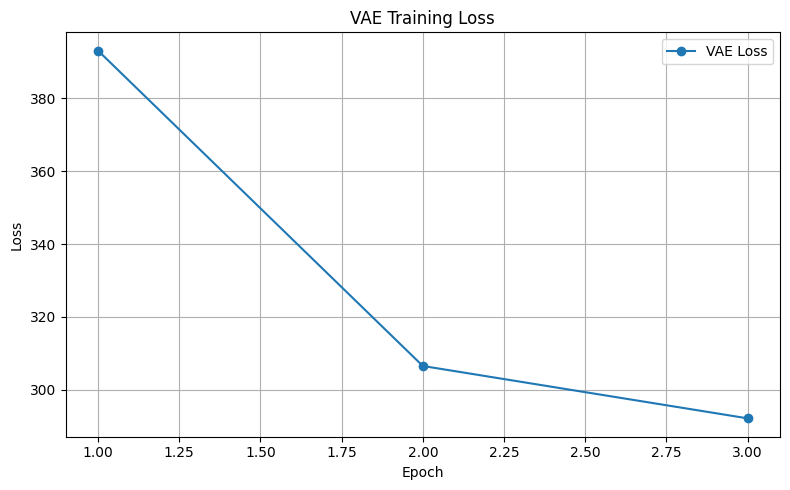

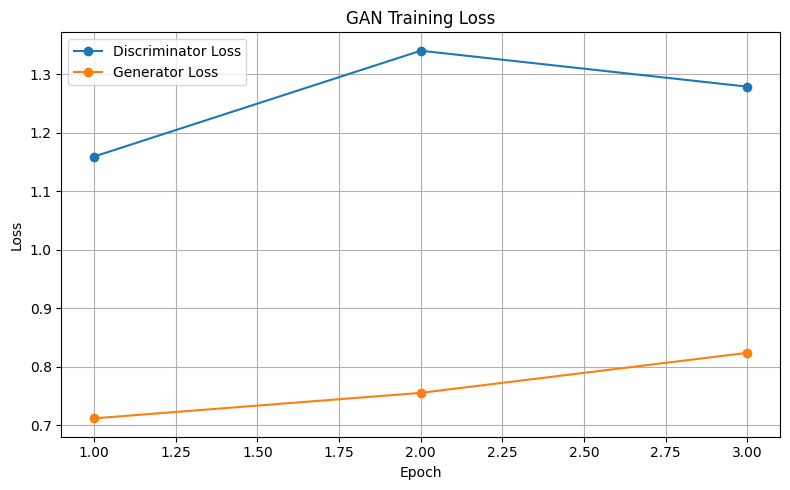


========== FINAL EVALUATION ==========
VAE Inception Score : 2.4764
GAN Inception Score : 2.8346
VAE FID Score      : 52.4679
GAN FID Score      : 31.4704
VAE Diversity      : 0.6299
GAN Diversity      : 0.7994

========== MODEL RECOMMENDATION ==========
GAN has lower FID and closer feature distribution to real data.
GAN achieved a higher classifier-based Inception Score.
GAN demonstrated higher class diversity.

EXPERIMENT 30 COMPLETED SUCCESSFULLY!


In [22]:
# ================================================================
# EXPERIMENT 30
# GENERATIVE MODEL OUTPUT COMPARISON AND EVALUATION
# VAE vs GAN using Fashion-MNIST
# Complete Google Colab Code - Single Cell
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, Model
from sklearn.decomposition import PCA
from scipy.linalg import sqrtm
from scipy.stats import entropy

# -------------------- INITIALIZATION --------------------
tf.keras.utils.set_random_seed(42)
np.random.seed(42)

print("TensorFlow Version:", tf.__version__)

# ================================================================
# 1. LOAD DATASET
# ================================================================

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# Subset for faster training
x_train = x_train[:10000]
y_train = y_train[:10000]

class_names = [
    "T-shirt", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Dataset Loaded Successfully")
print("Training Dataset Shape:", x_train.shape)
print("Testing Dataset Shape:", x_test.shape)

# ================================================================
# 2. TRAIN CLASSIFIER
# Used for IS, FID and generated class distribution
# ================================================================

classifier_input = layers.Input(shape=(28, 28, 1))

x = layers.Flatten()(classifier_input)
x = layers.Dense(256, activation="relu")(x)

feature_layer = layers.Dense(
    128, activation="relu", name="feature_layer"
)(x)

classifier_output = layers.Dense(
    10, activation="softmax"
)(feature_layer)

classifier = Model(classifier_input, classifier_output)

classifier.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nTraining Classifier...")

classifier.fit(
    x_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

feature_model = Model(
    classifier.input,
    classifier.get_layer("feature_layer").output
)

# ================================================================
# 3. BUILD VARIATIONAL AUTOENCODER (VAE)
# ================================================================

latent_dim = 2

vae_input = layers.Input(shape=(28, 28, 1))

x = layers.Flatten()(vae_input)
x = layers.Dense(256, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

def sampling(inputs):
    mean, log_var = inputs
    epsilon = tf.random.normal(tf.shape(mean))
    return mean + tf.exp(0.5 * log_var) * epsilon

z = layers.Lambda(sampling)([z_mean, z_log_var])

encoder = Model(
    vae_input,
    [z_mean, z_log_var, z],
    name="encoder"
)

# Decoder
decoder_input = layers.Input(shape=(latent_dim,))

x = layers.Dense(256, activation="relu")(decoder_input)
x = layers.Dense(784, activation="sigmoid")(x)
decoder_output = layers.Reshape((28, 28, 1))(x)

decoder = Model(
    decoder_input,
    decoder_output,
    name="decoder"
)

vae_output = decoder(z)
vae = Model(vae_input, vae_output, name="vae")

vae_optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# ================================================================
# 4. VAE TRAINING FUNCTION - CORRECTED
# ================================================================

@tf.function
def train_vae(images):

    with tf.GradientTape() as tape:

        mean, log_var, sampled_z = encoder(images, training=True)
        reconstructed = decoder(sampled_z, training=True)

        # Flatten images
        original = tf.reshape(images, [-1, 784])
        reconstructed_flat = tf.reshape(reconstructed, [-1, 784])

        reconstructed_flat = tf.clip_by_value(
            reconstructed_flat, 1e-7, 1.0 - 1e-7
        )

        # Pixel-wise binary cross entropy
        bce = -(
            original * tf.math.log(reconstructed_flat) +
            (1.0 - original) * tf.math.log(1.0 - reconstructed_flat)
        )

        # Sum across pixels, one value per image
        reconstruction_loss = tf.reduce_sum(bce, axis=1)

        # KL divergence
        kl_loss = -0.5 * tf.reduce_sum(
            1.0 + log_var - tf.square(mean) - tf.exp(log_var),
            axis=1
        )

        # Final VAE loss
        loss = tf.reduce_mean(reconstruction_loss + kl_loss)

    gradients = tape.gradient(loss, vae.trainable_variables)

    vae_optimizer.apply_gradients(
        zip(gradients, vae.trainable_variables)
    )

    return loss

# ================================================================
# 5. TRAIN VAE
# ================================================================

vae_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(10000)
    .batch(128)
)

vae_epochs = 3
vae_losses = []

print("\n========== TRAINING VAE ==========")

for epoch in range(vae_epochs):

    batch_losses = []

    for batch in vae_dataset:
        loss = train_vae(batch)
        batch_losses.append(float(loss))

    epoch_loss = np.mean(batch_losses)
    vae_losses.append(epoch_loss)

    print(
        f"VAE Epoch {epoch+1}/{vae_epochs} "
        f"| Loss: {epoch_loss:.4f}"
    )

# ================================================================
# 6. BUILD GENERATOR
# ================================================================

noise_input = layers.Input(shape=(100,))

x = layers.Dense(7 * 7 * 128)(noise_input)
x = layers.Reshape((7, 7, 128))(x)

x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

x = layers.Conv2DTranspose(
    64, kernel_size=4, strides=2, padding="same"
)(x)

x = layers.BatchNormalization()(x)
x = layers.ReLU()(x)

generator_output = layers.Conv2DTranspose(
    1, kernel_size=4, strides=2,
    padding="same", activation="tanh"
)(x)

generator = Model(noise_input, generator_output, name="generator")

# ================================================================
# 7. BUILD DISCRIMINATOR
# ================================================================

image_input = layers.Input(shape=(28, 28, 1))

x = layers.Conv2D(
    64, kernel_size=4, strides=2, padding="same"
)(image_input)

x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Conv2D(
    128, kernel_size=4, strides=2, padding="same"
)(x)

x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Dropout(0.3)(x)

x = layers.Flatten()(x)
discriminator_output = layers.Dense(1)(x)

discriminator = Model(
    image_input,
    discriminator_output,
    name="discriminator"
)

# ================================================================
# 8. GAN TRAINING CONFIGURATION
# ================================================================

g_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

d_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

# GAN requires images in [-1,1]
gan_images = (x_train * 2.0) - 1.0

gan_dataset = (
    tf.data.Dataset.from_tensor_slices(gan_images)
    .shuffle(10000)
    .batch(128, drop_remainder=True)
)

# ================================================================
# 9. GAN TRAINING FUNCTION
# ================================================================

@tf.function
def train_gan(real_images):

    batch_size = tf.shape(real_images)[0]

    # ---------------- DISCRIMINATOR ----------------
    noise = tf.random.normal((batch_size, 100))

    with tf.GradientTape() as tape:

        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        real_loss = bce(
            tf.ones_like(real_output), real_output
        )

        fake_loss = bce(
            tf.zeros_like(fake_output), fake_output
        )

        d_loss = real_loss + fake_loss

    d_gradients = tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    # ---------------- GENERATOR ----------------
    noise = tf.random.normal((batch_size, 100))

    with tf.GradientTape() as tape:

        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)

        g_loss = bce(
            tf.ones_like(fake_output), fake_output
        )

    g_gradients = tape.gradient(
        g_loss, generator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )

    return d_loss, g_loss

# ================================================================
# 10. TRAIN GAN
# ================================================================

gan_epochs = 3

d_losses = []
g_losses = []

print("\n========== TRAINING GAN ==========")

for epoch in range(gan_epochs):

    epoch_d_losses = []
    epoch_g_losses = []

    for batch in gan_dataset:

        d_loss, g_loss = train_gan(batch)

        epoch_d_losses.append(float(d_loss))
        epoch_g_losses.append(float(g_loss))

    avg_d_loss = np.mean(epoch_d_losses)
    avg_g_loss = np.mean(epoch_g_losses)

    d_losses.append(avg_d_loss)
    g_losses.append(avg_g_loss)

    print(
        f"GAN Epoch {epoch+1}/{gan_epochs} "
        f"| Discriminator Loss: {avg_d_loss:.4f} "
        f"| Generator Loss: {avg_g_loss:.4f}"
    )

# ================================================================
# 11. GENERATE 1000 IMAGES FROM EACH MODEL
# ================================================================

N = 1000

print("\nGenerating 1000 VAE images...")
vae_noise = np.random.normal(
    size=(N, latent_dim)
).astype("float32")

vae_generated = decoder.predict(vae_noise, verbose=0)

print("Generating 1000 GAN images...")
gan_noise = tf.random.normal((N, 100))

gan_generated = generator(
    gan_noise, training=False
).numpy()

# Convert [-1,1] to [0,1]
gan_generated = np.clip(
    (gan_generated + 1.0) / 2.0, 0, 1
)

print("VAE Images:", vae_generated.shape)
print("GAN Images:", gan_generated.shape)

# ================================================================
# 12. VISUALIZE GENERATED IMAGES
# ================================================================

def show_images(images, title):

    plt.figure(figsize=(8, 8))

    for i in range(25):

        plt.subplot(5, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

show_images(vae_generated, "VAE Generated Images")
show_images(gan_generated, "GAN Generated Images")

# ================================================================
# 13. CLASSIFIER PREDICTIONS
# ================================================================

print("\nClassifying generated images...")

vae_predictions = classifier.predict(
    vae_generated, batch_size=128, verbose=0
)

gan_predictions = classifier.predict(
    gan_generated, batch_size=128, verbose=0
)

real_predictions = classifier.predict(
    x_test[:N], batch_size=128, verbose=0
)

# ================================================================
# 14. CLASSIFIER-BASED INCEPTION SCORE
# ================================================================

def calculate_is(predictions, splits=5):

    scores = []
    split_size = len(predictions) // splits

    for i in range(splits):

        part = predictions[
            i * split_size:(i + 1) * split_size
        ]

        marginal = np.mean(part, axis=0)
        marginal = np.clip(marginal, 1e-10, 1.0)

        kl_values = []

        for p in part:

            p = np.clip(p, 1e-10, 1.0)

            kl_values.append(
                np.sum(p * np.log(p / marginal))
            )

        scores.append(np.exp(np.mean(kl_values)))

    return np.mean(scores), np.std(scores)

vae_is_mean, vae_is_std = calculate_is(vae_predictions)
gan_is_mean, gan_is_std = calculate_is(gan_predictions)

# ================================================================
# 15. FEATURE EXTRACTION
# ================================================================

print("\nExtracting features...")

real_features = feature_model.predict(
    x_test[:N], batch_size=128, verbose=0
)

vae_features = feature_model.predict(
    vae_generated, batch_size=128, verbose=0
)

gan_features = feature_model.predict(
    gan_generated, batch_size=128, verbose=0
)

# ================================================================
# 16. FID CALCULATION
# ================================================================

def calculate_fid(real_features, generated_features):

    real_features = np.asarray(real_features)
    generated_features = np.asarray(generated_features)

    mu1 = np.mean(real_features, axis=0)
    mu2 = np.mean(generated_features, axis=0)

    sigma1 = np.cov(real_features, rowvar=False)
    sigma2 = np.cov(generated_features, rowvar=False)

    diff = mu1 - mu2

    covmean = sqrtm(sigma1 @ sigma2)

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = (
        np.sum(diff ** 2)
        + np.trace(sigma1)
        + np.trace(sigma2)
        - 2 * np.trace(covmean)
    )

    return float(max(fid, 0))

vae_fid = calculate_fid(real_features, vae_features)
gan_fid = calculate_fid(real_features, gan_features)

# ================================================================
# 17. DIVERSITY ANALYSIS
# ================================================================

def calculate_diversity(predictions):

    predicted_classes = np.argmax(predictions, axis=1)

    counts = np.bincount(
        predicted_classes, minlength=10
    )

    probabilities = counts / np.sum(counts)

    diversity_entropy = entropy(
        probabilities + 1e-10
    )

    normalized_entropy = diversity_entropy / np.log(10)

    class_coverage = np.count_nonzero(counts)

    return (
        diversity_entropy,
        normalized_entropy,
        class_coverage,
        counts,
        probabilities
    )

vae_div = calculate_diversity(vae_predictions)
gan_div = calculate_diversity(gan_predictions)

# ================================================================
# 18. FINAL COMPARISON TABLE
# ================================================================

results = pd.DataFrame({
    "Evaluation Metric": [
        "Classifier-based Inception Score",
        "FID Score",
        "Diversity Entropy",
        "Normalized Diversity",
        "Class Coverage"
    ],

    "VAE": [
        round(vae_is_mean, 4),
        round(vae_fid, 4),
        round(vae_div[0], 4),
        round(vae_div[1], 4),
        vae_div[2]
    ],

    "GAN": [
        round(gan_is_mean, 4),
        round(gan_fid, 4),
        round(gan_div[0], 4),
        round(gan_div[1], 4),
        gan_div[2]
    ]
})

print("\n========== FINAL COMPARISON TABLE ==========")
display(results)

# ================================================================
# 19. GENERATED CLASS DISTRIBUTION
# ================================================================

distribution_df = pd.DataFrame({
    "Fashion Category": class_names,
    "VAE Generated Images": vae_div[3],
    "GAN Generated Images": gan_div[3]
})

print("\nGenerated Class Distribution")
display(distribution_df)

plt.figure(figsize=(12, 5))

positions = np.arange(10)
width = 0.35

plt.bar(
    positions - width/2,
    vae_div[3],
    width,
    label="VAE"
)

plt.bar(
    positions + width/2,
    gan_div[3],
    width,
    label="GAN"
)

plt.xticks(positions, class_names, rotation=45)
plt.xlabel("Fashion Category")
plt.ylabel("Number of Generated Images")
plt.title("VAE vs GAN Class Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# ================================================================
# 20. PCA FEATURE VISUALIZATION
# ================================================================

combined_features = np.vstack([
    real_features,
    vae_features,
    gan_features
])

pca = PCA(n_components=2)
pca_features = pca.fit_transform(combined_features)

real_pca = pca_features[:N]
vae_pca = pca_features[N:2*N]
gan_pca = pca_features[2*N:]

plt.figure(figsize=(10, 7))

plt.scatter(
    real_pca[:, 0], real_pca[:, 1],
    alpha=0.35, s=15, label="Real Images"
)

plt.scatter(
    vae_pca[:, 0], vae_pca[:, 1],
    alpha=0.4, s=15, label="VAE Images"
)

plt.scatter(
    gan_pca[:, 0], gan_pca[:, 1],
    alpha=0.4, s=15, label="GAN Images"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Real vs VAE vs GAN Feature Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# ================================================================
# 21. VAE TRAINING LOSS
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(vae_losses) + 1),
    vae_losses,
    marker="o",
    label="VAE Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ================================================================
# 22. GAN TRAINING LOSS
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(d_losses) + 1),
    d_losses,
    marker="o",
    label="Discriminator Loss"
)

plt.plot(
    range(1, len(g_losses) + 1),
    g_losses,
    marker="o",
    label="Generator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ================================================================
# 23. AUTOMATIC MODEL COMPARISON
# ================================================================

print("\n========== FINAL EVALUATION ==========")

print(f"VAE Inception Score : {vae_is_mean:.4f}")
print(f"GAN Inception Score : {gan_is_mean:.4f}")

print(f"VAE FID Score      : {vae_fid:.4f}")
print(f"GAN FID Score      : {gan_fid:.4f}")

print(f"VAE Diversity      : {vae_div[1]:.4f}")
print(f"GAN Diversity      : {gan_div[1]:.4f}")

print("\n========== MODEL RECOMMENDATION ==========")

if gan_fid < vae_fid:
    print("GAN has lower FID and closer feature distribution to real data.")
else:
    print("VAE has lower FID and closer feature distribution to real data.")

if gan_is_mean > vae_is_mean:
    print("GAN achieved a higher classifier-based Inception Score.")
else:
    print("VAE achieved a higher classifier-based Inception Score.")

if gan_div[1] > vae_div[1]:
    print("GAN demonstrated higher class diversity.")
else:
    print("VAE demonstrated higher class diversity.")

print("\nEXPERIMENT 30 COMPLETED SUCCESSFULLY!")